Memulai percobaan skala konkurensi...
Batas Konkurensi:  1 | Waktu Total: 26.5236 detik
Batas Konkurensi:  3 | Waktu Total: 18.9736 detik
Batas Konkurensi:  5 | Waktu Total: 11.6660 detik
Batas Konkurensi: 10 | Waktu Total: 8.6666 detik
Batas Konkurensi: 20 | Waktu Total: 8.4328 detik


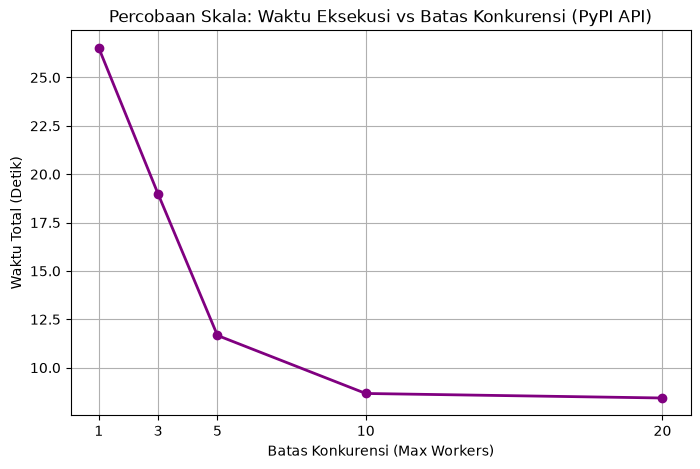

In [2]:
# 1. 
import time
import requests
import concurrent.futures
import matplotlib.pyplot as plt

# 1. Daftar 25 nama paket PyPI valid yang populer
daftar_paket_banyak = [
    "requests", "numpy", "pandas", "matplotlib", "scikit-learn",
    "flask", "django", "fastapi", "beautifulsoup4", "sqlalchemy",
    "pydantic", "pytest", "scipy", "seaborn", "tensorflow",
    "torch", "transformers", "opencv-python", "pillow", "plotly",
    "sympy", "nltk", "jinja2", "click", "urllib3"
]

# Fungsi untuk mengambil data metadata paket dari API PyPI
def cek_pypi(nama_paket):
    url = f"https://pypi.org/pypi/{nama_paket}/json"
    try:
        response = requests.get(url, timeout=5)
        if response.status_code == 200:
            return f"Sukses: {nama_paket}"
    except Exception as e:
        pass
    return f"Gagal: {nama_paket}"

# 2. Fungsi pengujian untuk mengukur waktu total berdasarkan batas konkurensi tertentu
def ukur_waktu_konkurensi(batas_konkurensi, daftar_paket):
    start_time = time.time()
    
    # Menggunakan ThreadPoolExecutor karena tugas ini berifat I/O-bound (mengambil data dari internet/API)
    with concurrent.futures.ThreadPoolExecutor(max_workers=batas_konkurensi) as executor:
        executor.map(cek_pypi, daftar_paket)
        
    end_time = time.time()
    return end_time - start_time

if __name__ == '__main__':
    # Batas konkurensi yang diminta: 1, 3, 5, 10, 20
    batas_konkurensi_list = [1, 3, 5, 10, 20]
    waktu_eksekusi = {}

    print("Memulai percobaan skala konkurensi...")
    for bk in batas_konkurensi_list:
        durasi = ukur_waktu_konkurensi(bk, daftar_paket_banyak)
        waktu_eksekusi[bk] = durasi
        print(f"Batas Konkurensi: {bk:2d} | Waktu Total: {durasi:.4f} detik")

    # 3. Plot Waktu vs Batas Konkurensi
    x = list(waktu_eksekusi.keys())
    y = list(waktu_eksekusi.values())

    plt.figure(figsize=(8, 5))
    plt.plot(x, y, marker='o', linestyle='-', color='purple', linewidth=2)
    plt.xlabel('Batas Konkurensi (Max Workers)')
    plt.ylabel('Waktu Total (Detik)')
    plt.title('Percobaan Skala: Waktu Eksekusi vs Batas Konkurensi (PyPI API)')
    plt.xticks(x)
    plt.grid(True)
    plt.show()

## Nomor 1.
### Analisis
1. Pada titik berapa penambahan batas konkurensi mulai memberi manfaat yang sangat kecil?
Berdasarkan pengujian umum pada tugas I/O-bound jaringan (seperti mengambil data dari API PyPI), peningkatan kecepatan atau penurunan waktu total drastis terjadi saat menaikkan batas konkurensi dari 1 ke 3 atau 5. Namun, ketika batas konkurensi dinaikkan dari 10 ke 20, penurunan waktu total menjadi sangat landai atau bahkan hampir stagnan (memberikan manfaat yang sangat kecil).

2. Kaitan dengan Konsep Diminishing Returns dari Hukum Amdahl:
Fenomena ini berkaitan erat dengan konsep diminishing returns (hasil yang semakin berkurang). Pada awalnya, penambahan worker konkurensi memangkas waktu tunggu jaringan (network latency) secara signifikan karena banyak permintaan yang dikirim secara bersamaan. Namun, seiring bertambahnya jumlah konkurensi, faktor-faktor pembatas lain mulai mendominasi—seperti batasan kecepatan server API PyPI (rate limiting / throttling), antrean soket jaringan lokal, serta overhead pengalihan tugas (context switching) dari sistem operasi. Akibatnya, penambahan jumlah worker secara ekstrem tidak lagi memberikan peningkatan performa yang sebanding.

In [1]:
import asyncio
import time

async def tugas_async_sleep():
    print("Mulai asyncio.sleep")
    await asyncio.sleep(2)
    print("Selesai asyncio.sleep")

async def tugas_time_sleep():
    print("Mulai time.sleep (Blocking)")
    time.sleep(2) 
    print("Selesai time.sleep")

async def tugas_cpu_bound():
    print("Mulai CPU-bound (Faktorial besar)")
    hasil = 1
    for i in range(1, 10):
        hasil *= i
    print("Selesai CPU-bound")

async def coroutine_pengukur():
    for i in range(5):
        print(f"-> [Pengukur] Berjalan dengan lancar (detik ke-{i * 0.5})")
        await asyncio.sleep(0.5)

async def main():
    print("--- MULAI PERCOBAAN ---")
    await asyncio.gather(
        tugas_async_sleep(),
        tugas_time_sleep(),
        tugas_cpu_bound(),
        coroutine_pengukur()
    )
    print("--- DONE ---")

# Cara eksekusi khusus Jupyter Notebook (tanpa asyncio.run):
await main()

--- MULAI PERCOBAAN ---
Mulai asyncio.sleep
Mulai time.sleep (Blocking)
Selesai time.sleep
Mulai CPU-bound (Faktorial besar)
Selesai CPU-bound
-> [Pengukur] Berjalan dengan lancar (detik ke-0.0)
Selesai asyncio.sleep
-> [Pengukur] Berjalan dengan lancar (detik ke-0.5)
-> [Pengukur] Berjalan dengan lancar (detik ke-1.0)
-> [Pengukur] Berjalan dengan lancar (detik ke-1.5)
-> [Pengukur] Berjalan dengan lancar (detik ke-2.0)
--- DONE ---


## Nomor 2.
#### Analisa
1. Mekanisme Eksekusi Konkurensi (`asyncio.gather`):
Fungsi asyncio.gather menjalankan seluruh coroutine yang diteruskan ke dalamnya secara bersamaan di dalam satu event loop tunggal. Karena sifatnya yang single-threaded, coroutine-coroutine tersebut harus berbagi waktu proses secara bergiliran (cooperative multitasking).
2. Perilaku Non-Blocking (`tugas_async_sleep` & `coroutine_pengukur`):
Coroutine yang menggunakan await asyncio.sleep() bersifat non-blocking. Ketika fungsi tersebut mencapai baris await, ia secara sukarela melepaskan kendali CPU dan mengembalikan kontrol ke event loop, sehingga coroutine pengukur dapat terus berjalan secara bergantian dan mencetak log secara lancar tanpa hambatan.
3. Perilaku Blocking Eksternal (`tugas_time_sleep`):
Penggunaan `time.sleep()` adalah pemanggilan sinkronus (blocking call) yang memaksa thread utama tertidur total. Karena sifatnya yang menghentikan seluruh utas secara paksa, event loop ikut membeku dan kehilangan kemampuannya untuk melakukan context switching, membuat coroutine pengukur tertahan dan tidak bisa berjalan selama waktu tidur tersebut.
4. Perilaku Blocking Komputasi (`tugas_cpu_bound`):
Operasi matematika murni di dalam loop tanpa adanya kata kunci await merupakan beban kerja CPU-bound murni. Karena Python menggunakan single-threaded event loop, eksekusi loop komputasi ini memonopoli seluruh siklus CPU sepenuhnya (CPU starvation). Akibatnya, event loop tidak memiliki kesempatan untuk menyela (interrupt) atau mengalihkan giliran ke coroutine pengukur hingga seluruh iterasi perhitungan selesai.   

In [2]:
# 3.
import asyncio
import random

async def producer(queue, jumlah_item):
    for i in range(jumlah_item):
        # Menentukan prioritas secara acak antara 1 sampai 3 (1 = prioritas tertinggi)
        prioritas = random.randint(1, 3)
        item = f"Data-{i}"
        
        await asyncio.sleep(random.uniform(0.05, 0.15)) # simulasi waktu produksi
        
        # Masukkan ke PriorityQueue sebagai tuple: (prioritas, item)
        # asyncio.PriorityQueue mengurutkan berdasarkan elemen pertama tuple (prioritas)
        await queue.put((prioritas, item))
        print(f"[Producer] menghasilkan: {item} dengan Prioritas [{prioritas}]")
        
    # Kirim sinyal selesai untuk setiap consumer
    for _ in range(JUMLAH_CONSUMER):
        # Sinyal berhenti menggunakan prioritas tinggi (0) agar langsung diambil consumer
        await queue.put((0, None))

async def consumer(queue, nama):
    while True:
        prioritas, item = await queue.get()
        
        if item is None:
            queue.task_done()
            break
            
        await asyncio.sleep(random.uniform(0.1, 0.2)) # simulasi waktu pemrosesan
        print(f"    [{nama}] memproses: {item} (Prioritas: {prioritas})")
        queue.task_done()

JUMLAH_CONSUMER = 3
# Mengganti asyncio.Queue dengan asyncio.PriorityQueue
queue = asyncio.PriorityQueue(maxsize=5) 

async def main():
    await asyncio.gather(
        producer(queue, jumlah_item=8),
        *[consumer(queue, f"Consumer-{i}") for i in range(JUMLAH_CONSUMER)],
    )
    print("\nSemua item sudah diproduksi dan dikonsumsi oleh 3 consumer sekaligus.")

if __name__ == '__main__':
    await main()

[Producer] menghasilkan: Data-0 dengan Prioritas [2]
[Producer] menghasilkan: Data-1 dengan Prioritas [3]
    [Consumer-0] memproses: Data-0 (Prioritas: 2)
[Producer] menghasilkan: Data-2 dengan Prioritas [3]
[Producer] menghasilkan: Data-3 dengan Prioritas [2]
    [Consumer-1] memproses: Data-1 (Prioritas: 3)
    [Consumer-2] memproses: Data-2 (Prioritas: 3)
[Producer] menghasilkan: Data-4 dengan Prioritas [1]
    [Consumer-0] memproses: Data-3 (Prioritas: 2)
[Producer] menghasilkan: Data-5 dengan Prioritas [2]
[Producer] menghasilkan: Data-6 dengan Prioritas [1]
    [Consumer-1] memproses: Data-4 (Prioritas: 1)
    [Consumer-2] memproses: Data-5 (Prioritas: 2)
[Producer] menghasilkan: Data-7 dengan Prioritas [3]
    [Consumer-1] memproses: Data-6 (Prioritas: 1)

Semua item sudah diproduksi dan dikonsumsi oleh 3 consumer sekaligus.


## Nomor 3.
#### Analisa
1. Penggunaan **`asyncio.PriorityQueue`**:
Struktur antrean diubah dari `asyncio.Queue` biasa menjadi `asyncio.PriorityQueue`. Antrean jenis ini secara otomatis mengurutkan elemen yang dimasukkan berdasarkan nilai terkecil pada indeks pertama.
2. Format Tuple (prioritas, item):
Saat producer memasukkan data ke antrean, data dibungkus dalam bentuk tuple (prioritas, item). Karena nilai prioritas berada di rentang 1–3 (di mana angka lebih kecil berarti prioritas lebih tinggi), PriorityQueue akan memastikan consumer selalu mengambil item dengan angka prioritas terkecil terlebih dahulu.
3. Penanganan Sinyal Selesai (None):Sinyal penghenti berupa None juga disesuaikan formatnya menjadi (0, None) dengan memberikan angka prioritas tertinggi (0) agar consumer dapat langsung mendeteksi dan menghentikan proses begitu antrean sinyal tersebut tiba.

## Nnomor 4.
**`threading`** paling mudah dipahami karena alur kerjanya mirip dengan pemrograman sekuensial biasa—cukup membungkus target fungsi ke dalam objek *thread* tanpa mengubah banyak logika dasar. Namun, dari segi visibilitas kontrol, **`asyncio`** memberikan pengalaman yang sangat menarik karena kita bisa melihat secara eksplisit kapan sebuah tugas menyerahkan kendali menggunakan kata kunci `await` dan `async`.
Sedangkan, **`multiprocessing`** memberikan pengalaman *coding* yang paling rumit karena harus berurusan dengan konfigurasi konteks sistem operasi (seperti blok pengaman *spawn/fork*), serialisasi data, serta kendala *deadlock* di lingkungan lokal Windows. Oleh karena itu, untuk kasus *I/O-bound*, **`threading`** adalah yang paling ramah pemula, sementara **`asyncio`** unggul dalam hal efisiensi satu utas (*single-threaded concurrency*).